<a href="https://colab.research.google.com/github/yunesmchaar/Data_Science_Project/blob/main/CNN_MODULE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [3]:
# Charger le dataset
fashion_mnist = tf.keras.datasets.fashion_mnist

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

print("Taille des images d'entraînement :", X_train.shape)
print("Taille des étiquettes :", y_train.shape)
print("Taille des images de test :", X_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Taille des images d'entraînement : (60000, 28, 28)
Taille des étiquettes : (60000,)
Taille des images de test : (10000, 28, 28)


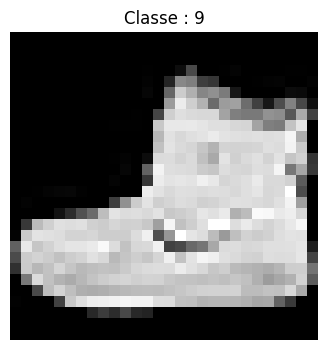

In [4]:
plt.figure(figsize=(4, 4))

plt.imshow(X_train[0], cmap="gray")
plt.title(f"Classe : {y_train[0]}")
plt.axis("off")

plt.show()

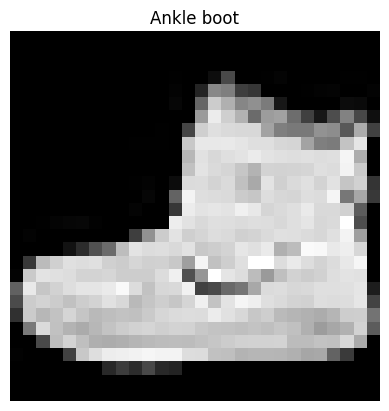

In [5]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

plt.imshow(X_train[0], cmap="gray")
plt.title(class_names[y_train[0]])
plt.axis("off")
plt.show()

In [6]:
# Normalisation des pixels
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Valeur minimale :", X_train.min())
print("Valeur maximale :", X_train.max())

Valeur minimale : 0.0
Valeur maximale : 1.0


In [7]:
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Nouvelle forme :", X_train.shape)

Nouvelle forme : (60000, 28, 28, 1)


In [8]:
model = tf.keras.Sequential([

    # Image d'entrée : 28 x 28 pixels, 1 canal
    tf.keras.layers.Input(shape=(28, 28, 1)),

    # Première convolution
    tf.keras.layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu"
    ),

    # Réduction des dimensions
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    # Deuxième convolution
    tf.keras.layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu"
    ),

    # Deuxième pooling
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    # Transformer les cartes en vecteur
    tf.keras.layers.Flatten(),

    # Couche dense
    tf.keras.layers.Dense(64, activation="relu"),

    # 10 classes
    tf.keras.layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
tf.keras.layers.Conv2D(
    filters=32,
    kernel_size=(3, 3),
    activation="relu"
)

<Conv2D name=conv2d_2, built=False>

In [11]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [12]:
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 45s 52ms/step - accuracy: 0.8098 - loss: 0.5304 - val_accuracy: 0.8467 - val_loss: 0.4169
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 44s 52ms/step - accuracy: 0.8759 - loss: 0.3460 - val_accuracy: 0.8857 - val_loss: 0.3242
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 81s 51ms/step - accuracy: 0.8912 - loss: 0.2996 - val_accuracy: 0.8980 - val_loss: 0.2855
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 43s 51ms/step - accuracy: 0.9033 - loss: 0.2648 - val_accuracy: 0.9037 - val_loss: 0.2786
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 82s 51ms/step - accuracy: 0.9121 - loss: 0.2411 - val_accuracy: 0.8982 - val_loss: 0.2721


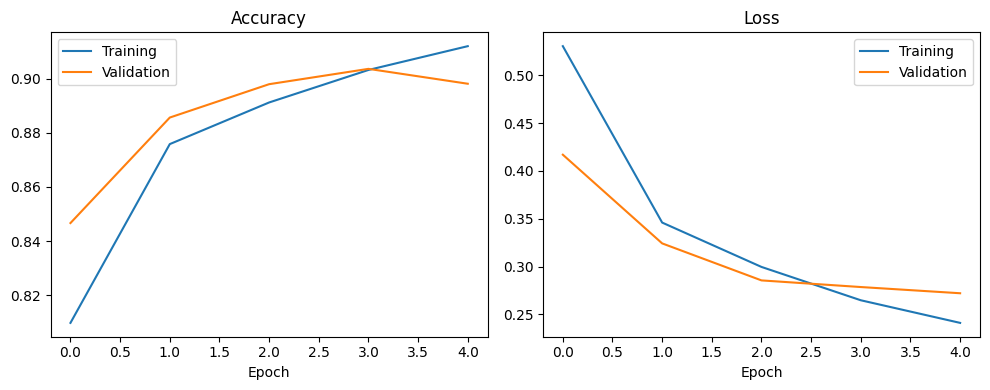

In [13]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

In [14]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)

Test loss: 0.2940012812614441
Test accuracy: 0.8931999802589417


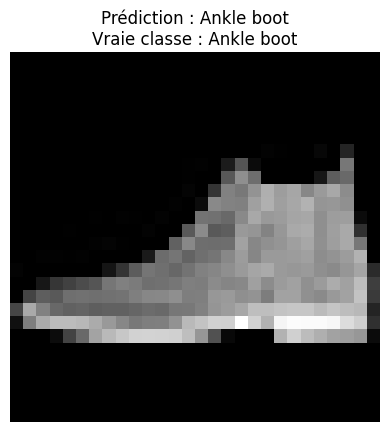

Probabilités : [6.6374923e-07 4.7651227e-10 1.7338207e-06 1.8306494e-08 4.2688423e-08
 4.0351952e-04 1.9805206e-07 2.0727464e-03 1.9966321e-06 9.9751914e-01]


In [15]:
index = 0

image = X_test[index]

# Le modèle attend un lot d'images
prediction = model.predict(
    image[np.newaxis, ...],
    verbose=0
)

predicted_class = np.argmax(prediction[0])
true_class = y_test[index]

plt.imshow(image.squeeze(), cmap="gray")
plt.title(
    f"Prédiction : {class_names[predicted_class]}\n"
    f"Vraie classe : {class_names[true_class]}"
)
plt.axis("off")
plt.show()

print("Probabilités :", prediction[0])